Procedural Terrain Morphing ,  β-VAE (Colab)
Train a Variational Autoencoder on real elevation patches, then export **only the decoder**
to ONNX for the Godot slider UI.

Run order:
  1. Run `tile_scraper.py` locally (see README) -> produces `patches.npy` (+ preview.png).
     Eyeball preview.png first: you want mountains/ridges, not ocean.
  2. Upload `patches.npy` to Colab (`/content/`) when the notebook asks.
  3. Runtime -> Change runtime type -> GPU, then Run all.

In [1]:
!pip install -q lightning onnx onnxruntime imageio  # uncomment if imports fail

import os, math, random, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split

try:
    import lightning.pytorch as pl
except ImportError:
    import pytorch_lightning as pl
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping

print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 126.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 124.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 65.2 MB/s eta 0:00:00
torch 2.9.0+cpu | cuda: False


In [2]:
!python /content/tile_scraper.py --regions himalayas andes --zoom 12 --target-patches 2000 --max-tiles 300 --out /content/data


48224 tiles cover the requested regions at z=12
Sampling 300 tiles...

Done: 2000 patches -> /content/data/patches.npy (2000, 64, 64) float32
Elevation range: 104 m to 6343 m
Tiles: {'downloaded': 223, 'flat': 97, 'failed': 0}
Preview contact sheet: preview.png - eyeball it before training.


In [3]:
CFG = dict(
    patches_path = "data/patches.npy",  # upload the scraper output here
    img_size     = 64,
    latent_dim   = 5,     # 5 sliders in Godot. If morphs look entangled, try 16 first to confirm the pipeline, then come back to 5.
    beta         = 4.0,   # β-VAE weight: higher = more disentangled sliders, but blurrier reconstructions
    kl_warmup_epochs = 15,
    lr           = 1e-3,
    batch_size   = 64,
    max_epochs   = 60,
    seed         = 42,
    val_frac     = 0.1,
)

def seed_all(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["seed"])

In [5]:
import os
print("cwd:", os.getcwd())
print("npy files:", [f for f in os.listdir('/content/data') if f.endswith('.npy')])

cwd: /content
npy files: ['patches.npy']


In [6]:
if not os.path.exists(CFG["patches_path"]):
    from google.colab import files
    print("Upload patches.npy from the tile scraper:")
    files.upload()  # then move it to /content/ if needed

raw = np.load(CFG["patches_path"]).astype(np.float32)  # (N, H, W) in METRES
print("loaded:", raw.shape, f"elev {raw.min():.0f}..{raw.max():.0f} m")

# Per-patch min-max -> [0, 1]. Each patch uses its full dynamic range,
# so every latent position decodes to terrain with real relief (no flat outputs).
mn = raw.reshape(len(raw), -1).min(1)[:, None, None]
mx = raw.reshape(len(raw), -1).max(1)[:, None, None]
rng = np.clip(mx - mn, 1e-6, None)
X = (raw - mn) / rng
X = X[(mx - mn).ravel() > 1.0]  # drop degenerate patches
print("kept patches:", len(X))

X = torch.from_numpy(X[:, None])  # (N, 1, H, W)
ds = TensorDataset(X, X)
n_val = max(1, int(len(ds) * CFG["val_frac"]))
train_ds, val_ds = random_split(ds, [len(ds) - n_val, n_val],
                                generator=torch.Generator().manual_seed(CFG["seed"]))
train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=CFG["batch_size"], num_workers=2)
print(f"train {len(train_ds)} / val {len(val_ds)}")

loaded: (2000, 64, 64) elev 104..6343 m
kept patches: 2000
train 1800 / val 200


In [7]:
class TerrainVAE(pl.LightningModule):
    def __init__(self, img_size=64, latent_dim=5, beta=4.0, kl_warmup_epochs=15, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.beta, self.kl_warmup_epochs, self.lr = beta, kl_warmup_epochs, lr

        # Encoder: 64 -> 32 -> 16 -> 8 -> 4 -> 2  (channels 1->32->64->128->128->128)
        enc, c = [], 1
        for out_c in [32, 64, 128, 128, 128]:
            enc += [nn.Conv2d(c, out_c, 4, 2, 1), nn.BatchNorm2d(out_c), nn.ReLU()]
            c = out_c
        self.encoder_conv = nn.Sequential(*enc)

        with torch.no_grad():
            conv_out = self.encoder_conv(torch.zeros(1, 1, img_size, img_size))
        self.conv_shape = conv_out.shape[1:]          # (128, 2, 2)
        flat = int(np.prod(self.conv_shape))         # 512

        # THE BOTTLENECK: conv features -> mu / logvar -> 5-dim latent vector
        self.fc_mu     = nn.Linear(flat, latent_dim)
        self.fc_logvar = nn.Linear(flat, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, flat)

        # Decoder: (128,2,2) -> ... -> (1,64,64), outputs LOGITS (no sigmoid here)
        dec, pairs = [], [(128, 128), (128, 128), (128, 64), (64, 32), (32, 1)]
        for i, (ic, oc) in enumerate(pairs):
            dec.append(nn.ConvTranspose2d(ic, oc, 4, 2, 1))
            if i < len(pairs) - 1:
                dec += [nn.BatchNorm2d(oc), nn.ReLU()]
        self.decoder_conv = nn.Sequential(*dec)

    def encode(self, x):
        h = self.encoder_conv(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(logvar)

    def decode(self, z):
        return self.decoder_conv(self.fc_decode(z).view(-1, *self.conv_shape))

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

    def _beta_now(self):
        if self.kl_warmup_epochs <= 0:
            return self.beta
        return self.beta * min(1.0, self.current_epoch / self.kl_warmup_epochs)

    def _loss(self, logits, x, mu, logvar):
        # BCE summed over pixels, averaged over batch  +  β * KL summed over latent dims, averaged over batch.
        # Both terms are per-sample means, so beta actually means something.
        recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / x.size(0)
        kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1).mean()
        beta = self._beta_now()
        return recon + beta * kl, recon, kl, beta

    def training_step(self, batch, batch_idx):
        x, _ = batch
        logits, mu, logvar = self(x)
        loss, recon, kl, beta = self._loss(logits, x, mu, logvar)
        self.log_dict({"train_loss": loss, "train_recon": recon, "train_kl": kl, "beta": beta},
                      prog_bar=True, on_epoch=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, _ = batch
        logits, mu, logvar = self(x)
        loss, recon, kl, _ = self._loss(logits, x, mu, logvar)
        self.log_dict({"val_loss": loss, "val_recon": recon, "val_kl": kl}, prog_bar=True)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)

model = TerrainVAE(**{k: CFG[k] for k in
    ["img_size", "latent_dim", "beta", "kl_warmup_epochs", "lr"]})
print(model)

TerrainVAE(
  (encoder_conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): Conv2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
  )
  (fc_mu): Linear(in_features=512, out_fea

In [8]:
ckpt = ModelCheckpoint(monitor="val_loss", save_top_k=1, mode="min",
                       filename="terrain-vae-{epoch:02d}-{val_loss:.4f}")
early = EarlyStopping(monitor="val_loss", patience=10, mode="min")
trainer = pl.Trainer(max_epochs=CFG["max_epochs"], accelerator="auto", devices=1,
                     callbacks=[ckpt, early], default_root_dir="/content/terrain_vae")
trainer.fit(model, train_loader, val_loader)
print("best checkpoint:", ckpt.best_model_path)

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: True, using: 1 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: True, using: 1 TPU cores
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments plat

┏━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name         ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder_conv │ Sequential │  690 K │ train │     0 │
│ 1 │ fc_mu        │ Linear     │  2.6 K │ train │     0 │
│ 2 │ fc_logvar    │ Linear     │  2.6 K │ train │     0 │
│ 3 │ fc_decode    │ Linear     │  3.1 K │ train │     0 │
│ 4 │ decoder_conv │ Sequential │  689 K │ train │     0 │
└───┴──────────────┴────────────┴────────┴───────┴───────┘

Trainable params: 1.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.4 M                                                                                                
Total estimated model params size (MB): 5.552                                                                      
Modules in train mode: 33                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is 
set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:321: The number of training batches 
(29) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if
you want to see logs for the training epoch.

best checkpoint: /content/terrain_vae/lightning_logs/version_0/checkpoints/terrain-vae-epoch=06-val_loss=2395.4106.ckpt


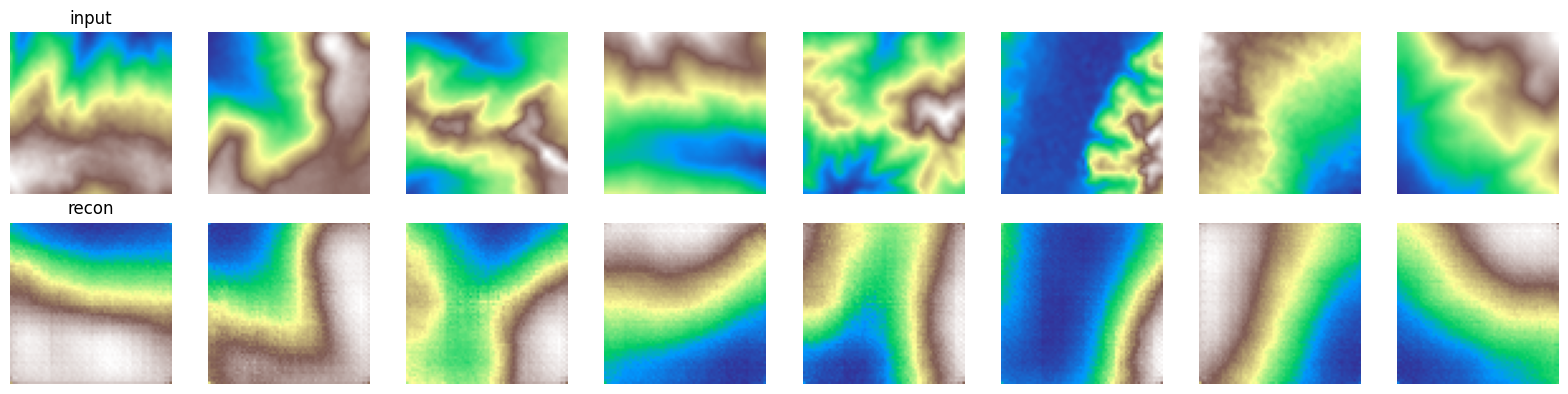

In [9]:
import matplotlib.pyplot as plt
model.eval()
xb, _ = next(iter(val_loader))
xb = xb[:8].to(model.device)
with torch.no_grad():
    recon_logits, _, _ = model(xb)
recon = torch.sigmoid(recon_logits).cpu()

fig, ax = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    ax[0, i].imshow(xb[i, 0].cpu(), cmap="terrain"); ax[0, i].axis("off")
    ax[1, i].imshow(recon[i, 0], cmap="terrain");  ax[1, i].axis("off")
ax[0, 0].set_title("input"); ax[1, 0].set_title("recon")
plt.tight_layout(); plt.show()

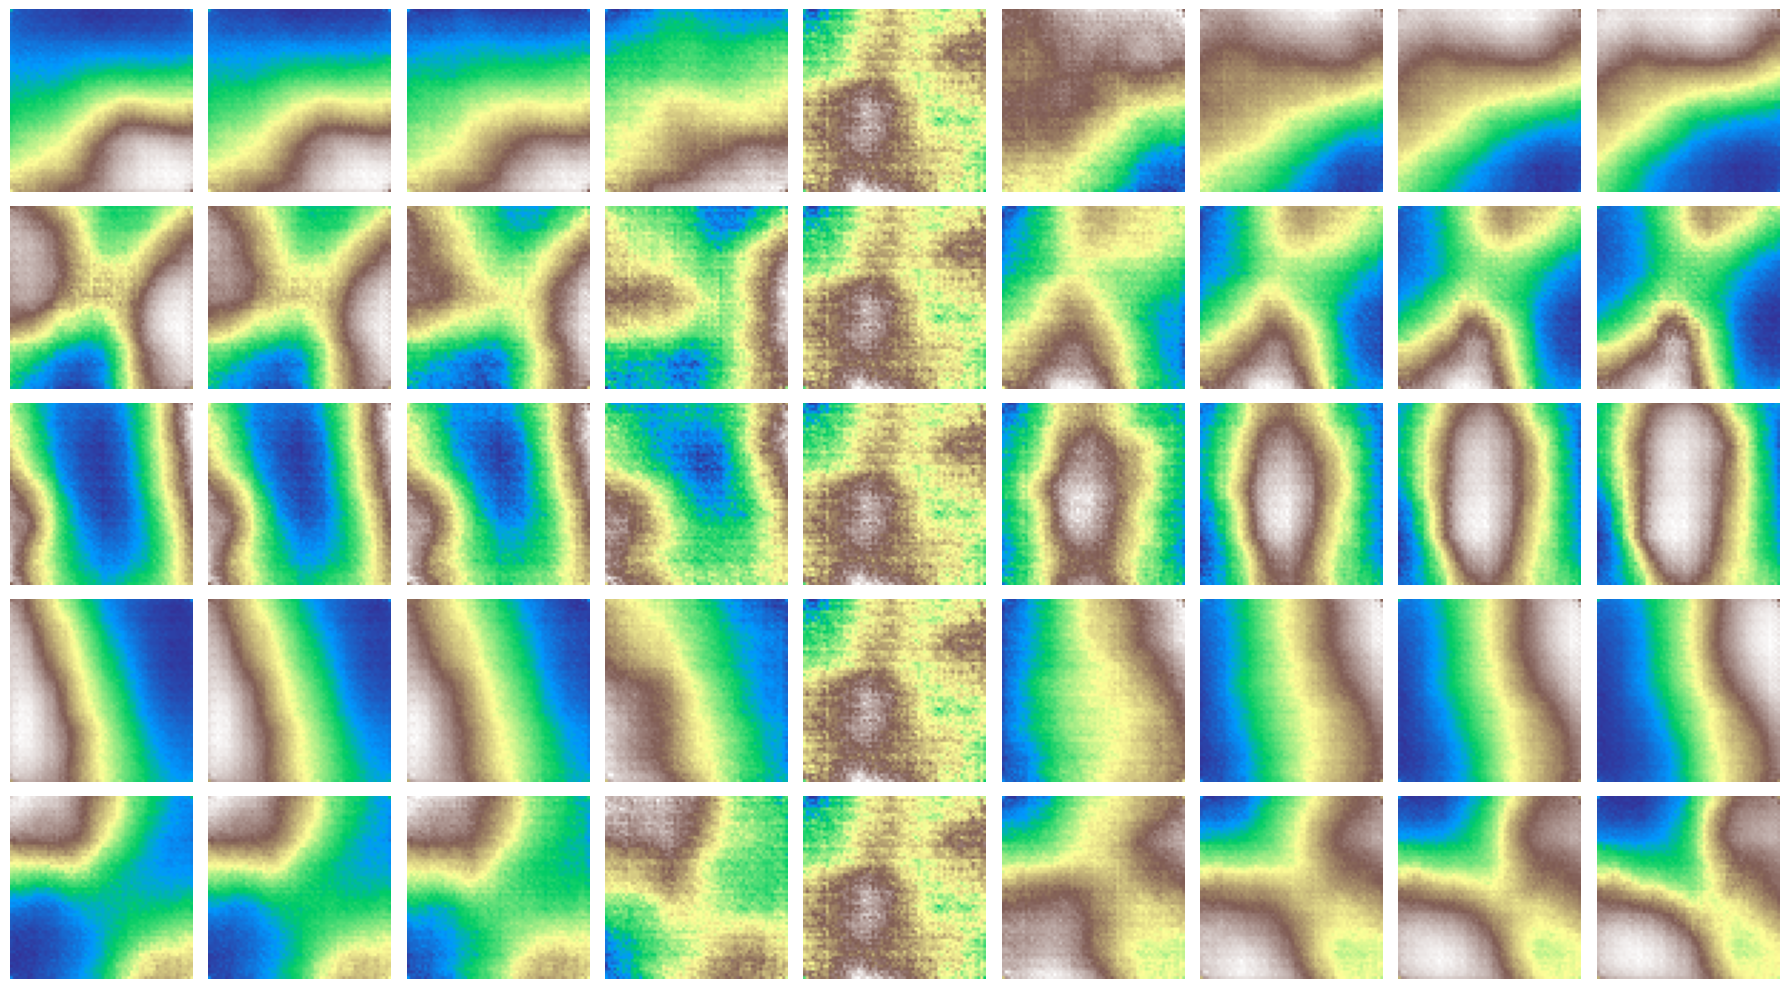

In [10]:
# One row per latent dim, sweeping -3..3. If a row barely changes, that dim collapsed:
# raise beta slightly or train longer. If one slider changes everything, dims are entangled:
# raise beta more (at the cost of blurrier recons).
model.eval()
steps = 9
fig, axes = plt.subplots(CFG["latent_dim"], steps, figsize=(2 * steps, 2 * CFG["latent_dim"]))
with torch.no_grad():
    for d in range(CFG["latent_dim"]):
        for j, v in enumerate(torch.linspace(-3, 3, steps)):
            z = torch.zeros(1, CFG["latent_dim"], device=model.device)
            z[0, d] = v
            img = torch.sigmoid(model.decode(z))[0, 0].cpu()
            axes[d, j].imshow(img, cmap="terrain"); axes[d, j].axis("off")
        axes[d, 0].set_ylabel(f"z[{d}]", rotation=0, labelpad=20, fontsize=12)
plt.tight_layout(); plt.show()

saved /content/morph.gif


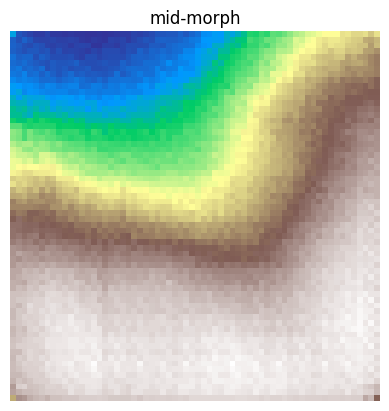

In [11]:
import imageio
model.eval()
xa, _ = next(iter(val_loader)); xa = xa.to(model.device)
with torch.no_grad():
    mua, _ = model.encode(xa[:1]); mub, _ = model.encode(xa[1:2])
    frames = []
    for t in np.linspace(0, 1, 30):
        z = (1 - t) * mua + t * mub
        img = torch.sigmoid(model.decode(z))[0, 0].cpu().numpy()
        frames.append((img * 255).astype(np.uint8))
imageio.mimsave("/content/morph.gif", frames, fps=10)
print("saved /content/morph.gif")
plt.imshow(frames[15], cmap="terrain"); plt.axis("off"); plt.title("mid-morph"); plt.show()

In [15]:
!pip install -q onnx onnxruntime onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 18.9 MB/s eta 0:00:00


In [16]:
# Fixed input (1, latent_dim), eval mode (freezes BatchNorm), opset 14 for plugin compat.
class DecoderOnly(nn.Module):
    def __init__(self, vae):
        super().__init__()
        self.vae = vae
    def forward(self, z):                       # z: (B, latent_dim) in [-3, 3]
        return torch.sigmoid(self.vae.decode(z))  # (B, 1, 64, 64) in [0, 1]

dec = DecoderOnly(model).eval()
dummy = torch.randn(1, CFG["latent_dim"])
onnx_path = "/content/terrain_decoder.onnx"
torch.onnx.export(dec, dummy, onnx_path,
                  input_names=["latent"], output_names=["heightmap"],
                  dynamic_axes={"latent": {0: "batch"}, "heightmap": {0: "batch"}},
                  opset_version=14)
print("exported", onnx_path, f"{os.path.getsize(onnx_path)/1024:.0f} KB")

# Verify the ONNX graph agrees with PyTorch
import onnxruntime as ort
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
z = np.random.randn(1, CFG["latent_dim"]).astype(np.float32)
with torch.no_grad():
    ref = dec(torch.from_numpy(z)).numpy()
got = sess.run(["heightmap"], {"latent": z})[0]
print("max abs diff pytorch vs onnx:", np.abs(ref - got).max())

/tmp/ipykernel_402/330817554.py:12: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(dec, dummy, onnx_path,
W1003 14:13:19.643000 402 torch/onnx/_internal/exporter/_compat.py:114] Setting ONNX exporter to use operator set version 18 because the requested opset_version 14 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W1003 14:13:20.330000 402 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampl

[torch.onnx] Obtain model graph for `DecoderOnly([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DecoderOnly([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/BaseConverter.h:66: adapter_lookup: Ass

[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
exported /content/terrain_decoder.onnx 23 KB
max abs diff pytorch vs onnx: 1.7881393e-07


In [17]:
# 16-bit PNGs preserve elevation steps; in Godot read as FORMAT_RF/RH float texture for the shader.
from PIL import Image as PILImage
os.makedirs("/content/godot_heightmaps", exist_ok=True)
model.eval()
with torch.no_grad():
    for i in range(4):
        z = torch.randn(1, CFG["latent_dim"], device=model.device) * 1.5
        h = torch.sigmoid(model.decode(z))[0, 0].cpu().numpy()
        PILImage.fromarray((h * 65535).astype(np.uint16)).save(f"/content/godot_heightmaps/h_{i}.png")
print("saved 4 test heightmaps to /content/godot_heightmaps/")

saved 4 test heightmaps to /content/godot_heightmaps/


In [19]:
!zip -r all_files.zip /content/* -x "*.ipynb"


  adding: content/data/ (stored 0%)
  adding: content/data/preview.png (deflated 0%)
  adding: content/data/patches.npy (deflated 70%)
  adding: content/data/meta.json (deflated 37%)
  adding: content/godot_heightmaps/ (stored 0%)
  adding: content/godot_heightmaps/h_0.png (stored 0%)
  adding: content/godot_heightmaps/h_2.png (stored 0%)
  adding: content/godot_heightmaps/h_1.png (stored 0%)
  adding: content/godot_heightmaps/h_3.png (stored 0%)
  adding: content/morph.gif (deflated 19%)
  adding: content/terrain_decoder.onnx (deflated 84%)
  adding: content/terrain_decoder.onnx.data (deflated 7%)
  adding: content/terrain_vae/ (stored 0%)
  adding: content/terrain_vae/lightning_logs/ (stored 0%)
  adding: content/terrain_vae/lightning_logs/version_0/ (stored 0%)
  adding: content/terrain_vae/lightning_logs/version_0/hparams.yaml (stored 0%)
  adding: content/terrain_vae/lightning_logs/version_0/metrics.csv (deflated 57%)
  adding: content/terrain_vae/lightning_logs/version_0/checkpoi